# Recurrent Neural Network (LSTM)
###### TImeseries(climate) using PyTorch

Import dependencies

In [1]:
import os
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
%matplotlib inline

### Pre-process data

seed random number generators

In [2]:
%%capture
rng = np.random.default_rng(seed=42)
torch.manual_seed(42)

Paramaters

In [3]:
seq_len = 50  # Sequence Length
train_test_ratio = 0.7

In [4]:
time_series = []  # float values in ppm
time_stamps = []  # string corresponding to year-month

read from data from csv file

In [5]:
csv_path = 'datasets/co2-ppm-mauna-loa-19651980.csv'
if not os.path.exists(csv_path):
    csv_path = os.path.join(os.path.dirname(__file__), '..', csv_path)

with open(csv_path) as f:
    next(f)  # skip header
    for line in f:
        try:
            line_parts = line.strip().split(',')
            time_series.append([float(line_parts[1])])
            time_stamps.append(line_parts[0].strip('"'))
        except Exception:
            break

time_series = np.array(time_series, dtype=np.float32)

Scale data

In [6]:
ts_min = np.min(time_series)
ts_max = np.max(time_series)

time_series = (time_series - ts_min) / (ts_max - ts_min)

Split data into train and test

In [7]:
train_time_series = time_series[:int(len(time_series) * train_test_ratio)]
test_time_series = time_series[int(len(time_series) * train_test_ratio) - 1:]

Creates sequences from data

In [8]:
def create_dataset(data, len_seq):
    features = []
    labels = []
    for i in range(len(data) - len_seq):
        features.append(data[i:i + len_seq])
        labels.append(data[i + len_seq])
    return np.array(features, dtype=np.float32), np.array(labels, dtype=np.float32)


trainX, trainY = create_dataset(train_time_series, seq_len)
testX, testY = create_dataset(
    np.concatenate((trainX[-1], test_time_series)), seq_len)

create datasets and dataloaders (shuffle=False is crucial for time series to preserve sequential temporal order)

In [9]:
train_dataset = TensorDataset(
    torch.tensor(trainX, dtype=torch.float32),
    torch.tensor(trainY, dtype=torch.float32))
test_dataset = TensorDataset(
    torch.tensor(testX, dtype=torch.float32),
    torch.tensor(testY, dtype=torch.float32))

train_loader = DataLoader(
    train_dataset, batch_size=len(train_dataset), shuffle=False)
test_loader = DataLoader(
    test_dataset, batch_size=len(test_dataset), shuffle=False)

trainX_t, trainY_t = next(iter(train_loader))
testX_t, testY_t = next(iter(test_loader))

## Neural Network

hyper-parameters

In [10]:
n_rnn_neurons = 100
n_input_neurons = 1
n_output_neurons = 1

learn_rate = 0.006

n_epoch = 1000

#### Model

In [11]:
class LSTMTimeSeries(nn.Module):

    def __init__(self, in_dim, hidden_dim, out_dim):
        super().__init__()
        self.lstm = nn.LSTM(in_dim, hidden_dim, batch_first=True)
        self.dropout = nn.Dropout(0.25)
        self.fc = nn.Linear(hidden_dim, out_dim)
        nn.init.normal_(self.fc.weight, std=1.0)
        nn.init.normal_(self.fc.bias, std=1.0)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        lstm_out, _ = self.lstm(x)
        lstm_op = lstm_out[:, -1, :]
        lstm_op = self.dropout(lstm_op)
        final_op = self.sigmoid(self.fc(lstm_op))
        return final_op


model = LSTMTimeSeries(n_input_neurons, n_rnn_neurons, n_output_neurons)

#### Error and Optimizer

In [12]:
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=learn_rate)


def train_step(x, y):
    # set to trainig mode
    model.train()
    # clear gradients
    optimizer.zero_grad()
    # forward pass
    pred_op = model(x)
    # calculate loss
    loss = 0.5 * criterion(pred_op, y)
    # calculate backpropogation gradient 
    loss.backward()
    # update the model weights
    optimizer.step()
    return loss.item()

#### Start Training

In [13]:
print("*********** Train ***********")

for epoch in range(n_epoch):
    err = train_step(trainX_t, trainY_t)

    if epoch % 100 == 0:
        print(f"Epoch : {epoch} Error = {float(err):f}")

*********** Train ***********
Epoch : 0 Error = 0.057603
Epoch : 100 Error = 0.001327
Epoch : 200 Error = 0.000321
Epoch : 300 Error = 0.000293
Epoch : 400 Error = 0.000260
Epoch : 500 Error = 0.000202
Epoch : 600 Error = 0.000196
Epoch : 700 Error = 0.000263
Epoch : 800 Error = 0.000206
Epoch : 900 Error = 0.000230


#### Testing

In [14]:
print("\n*********** Test ***********")

model.eval()
with torch.no_grad():
    resultt = model(testX_t)
    err = 0.5 * criterion(resultt, testY_t)
print(f"Testing Error : {float(err.item()):f}")
resultt = resultt.numpy()

# Predict future values with continuous data
inp = trainX[-1].flatten().tolist()
resultp = []

for i in range(len(test_time_series)):
    x_in = torch.tensor(inp, dtype=torch.float32).reshape(1, -1, 1)
    with torch.no_grad():
        op = model(x_in).numpy()
    inp.append(op[0][0])
    resultp.append(op[0][0])
    del inp[0]


*********** Test ***********
Testing Error : 0.001357


#### Plot test and prediction output

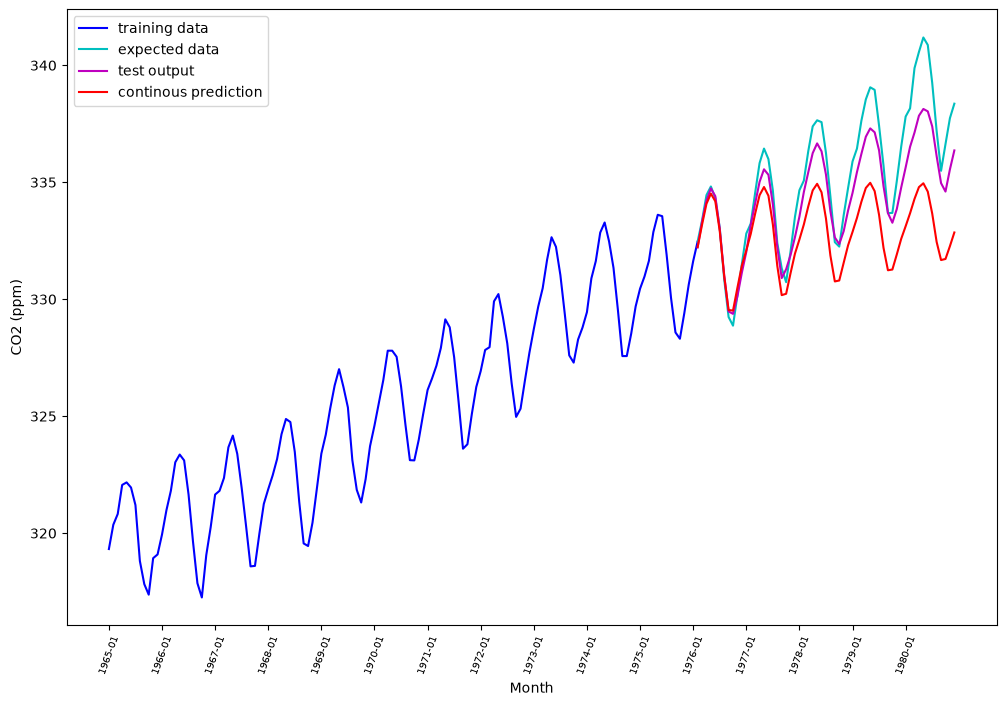

In [15]:
plt.figure(figsize=(12, 8))

plt.plot(
    train_time_series * (ts_max - ts_min) + ts_min,
    'b',
    label='training data')
plt.plot(
    np.arange(len(train_time_series) - 1, len(time_series)),
    test_time_series * (ts_max - ts_min) + ts_min,
    'c',
    label='expected data')
plt.plot(
    np.arange(len(train_time_series) - 1, len(time_series)),
    resultt * (ts_max - ts_min) + ts_min,
    'm',
    label='test output')
plt.plot(
    np.arange(len(train_time_series) - 1, len(time_series)),
    np.array(resultp) * (ts_max - ts_min) + ts_min,
    'r',
    label='continous prediction')

plt.xticks(
    np.arange(0, len(time_series), 12),
    time_stamps[::12],
    rotation=70,
    fontsize=7)
plt.xlabel('Month')
plt.ylabel('CO2 (ppm)')
plt.legend(loc='upper left')
plt.show()